In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.api import VAR
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings
from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import jarque_bera
warnings.filterwarnings("ignore")
plt.rcParams.update({'figure.figsize': (14, 7), 'axes.grid': True})

### Carga de Datos

In [2]:
df = pd.read_excel('datosUVR_IPC_TRM.xlsx', sheet_name='Datos')
df.columns = ['Fecha', 'UVR', 'IPC', 'TRM']
df['Fecha'] = pd.to_datetime(df['Fecha'])
df.set_index('Fecha', inplace=True)
df = df.asfreq('M')

# Imputación de datos vacíos
df['IPC'] = df['IPC'].ffill()
df['TRM'] = df['TRM'].ffill()

### Estacionariedad

In [3]:
def prueba_adf(serie, nombre):
    resultado = adfuller(serie.dropna())
    p_valor = resultado[1]
    estatus = "Estacionaria (I(0))" if p_valor < 0.05 else "NO Estacionaria"
    print(f" p-valor: {p_valor:.4f} | {estatus}")

print("TEST DE DICKEY-FULLER AUMENTADO")
prueba_adf(df['UVR'], "UVR Original")
prueba_adf(df['IPC'], "IPC Original")
prueba_adf(df['TRM'], "TRM Original")

TEST DE DICKEY-FULLER AUMENTADO
 p-valor: 0.9943 | NO Estacionaria
 p-valor: 0.9946 | NO Estacionaria
 p-valor: 0.1047 | NO Estacionaria


### Estabilidad

In [4]:
print("\n ESTABILIDAD DEL SISTEMA VAR")
modelo_var = VAR(df[['IPC', 'TRM']])
resultado_var = modelo_var.fit(maxlags=6)
es_estable = resultado_var.is_stable(verbose=True)
if es_estable:
    print("\nEl sistema VAR es ESTABLE (Todas las raíces están dentro del círculo unitario).")
else:
    print("\nADVERTENCIA: El sistema VAR es INESTABLE.")


 ESTABILIDAD DEL SISTEMA VAR
Eigenvalues of VAR(1) rep
0.5625408058919834
0.5625408058919834
0.4627918179049446
0.4627918179049446
0.7320867134192285
0.7320867134192285
0.1876876672501379
0.6985351426202686
0.6985351426202686
0.6273013741117376
0.9696950425407119
0.9969784988431241

El sistema VAR es ESTABLE (Todas las raíces están dentro del círculo unitario).


### División de datos

In [5]:
fecha_corte = '2024-10-31'

# Entrenamiento (Lo que el modelo "conoce")
df_train = df.loc[:fecha_corte]

# Validación empírica (Los 2 años que usamos para medir el error)
df_real_val = df.loc['2024-11-30':'2026-10-31'] 

horizonte_10_anios = 120 # Proyectar 10 años desde Nov 2024

print(f"Fin de entrenamiento: {df_train.index[-1].date()}")
print(f"Período de validación real: {df_real_val.index[0].date()} a {df_real_val.index[-1].date()}")

Fin de entrenamiento: 2024-10-31
Período de validación real: 2024-11-30 a 2026-10-31


### Proyección exogenas

In [6]:
exog_train = df_train[['IPC', 'TRM']]
modelo_var = VAR(exog_train)
res_var = modelo_var.fit(maxlags=6, ic='aic')

# Proyectar exógenas por 120 meses
pred_exog_10y = res_var.forecast(exog_train.values[-res_var.k_ar:], steps=horizonte_10_anios)

# Generar fechas futuras (Nov 2024 a Oct 2034)
fechas_10y = pd.date_range(start=df_train.index.max() + pd.offsets.MonthEnd(1), periods=horizonte_10_anios, freq='M')
df_exog_10y = pd.DataFrame(pred_exog_10y, index=fechas_10y, columns=['IPC', 'TRM'])

### Sarimax

In [7]:
y_train = df_train['UVR']

print("\nAjustando SARIMAX")
modelo_sarimax = SARIMAX(
    endog=y_train,
    exog=exog_train,
    order=(1, 1, 1),
    seasonal_order=(0, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)
res_sarimax = modelo_sarimax.fit(disp=False)

pronostico_10y = res_sarimax.get_forecast(steps=horizonte_10_anios, exog=df_exog_10y)
df_proyeccion_10y = pd.DataFrame({
    'UVR_Proyectada': pronostico_10y.predicted_mean,
    'Limite_Inferior': pronostico_10y.conf_int(alpha=0.05).iloc[:, 0],
    'Limite_Superior': pronostico_10y.conf_int(alpha=0.05).iloc[:, 1]
}, index=fechas_10y)

print("\nProyección de la UVR")
display(df_proyeccion_10y.head())



Ajustando SARIMAX

Proyección de la UVR


,UVR_Proyectada,Limite_Inferior,Limite_Superior
2024-11-30,377.022650,375.889954,378.155346
2024-12-31,377.091454,374.979663,379.203245
2025-01-31,377.213191,374.516431,379.909951
2025-02-28,378.278869,375.094100,381.463639
2025-03-31,381.334309,377.728249,384.940369


### Metricas de error

In [8]:
uvr_predicha_24m = df_proyeccion_10y.loc['2024-11-30':'2026-10-31', 'UVR_Proyectada']
uvr_real_24m = df_real_val['UVR']

rmse = np.sqrt(mean_squared_error(uvr_real_24m, uvr_predicha_24m))
mae = mean_absolute_error(uvr_real_24m, uvr_predicha_24m)
mape = np.mean(np.abs((uvr_real_24m - uvr_predicha_24m) / uvr_real_24m)) * 100

print("MÉTRICAS DE ERROR")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"MAPE : {mape:.4f} %")

MÉTRICAS DE ERROR
RMSE : 3.3942
MAE  : 2.8892
MAPE : 0.7164 %


### Gráficos

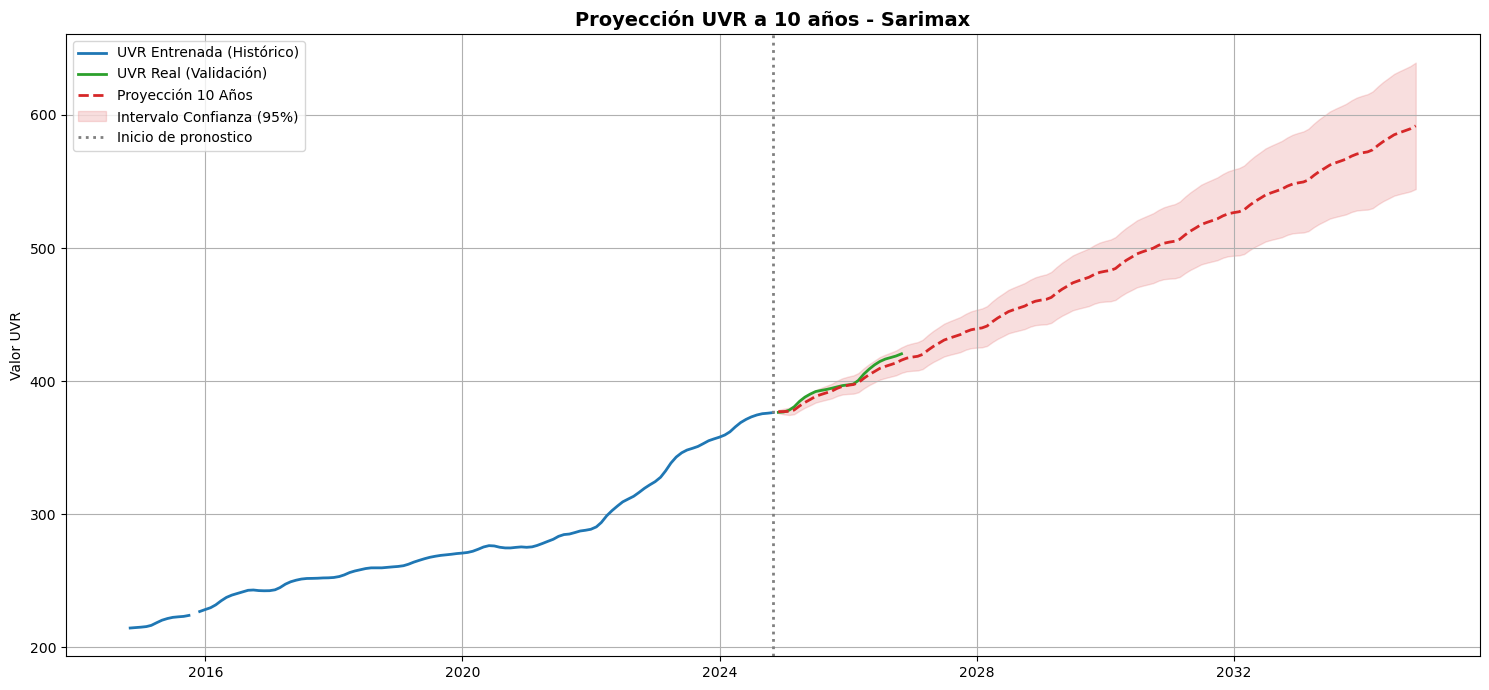

In [9]:
fig, ax = plt.subplots(figsize=(15, 7))

# Datos de entrenamiento
ax.plot(df_train.index, df_train['UVR'], color='#1f77b4', linewidth=2, label='UVR Entrenada (Histórico)')

# Datos reales usados para validar
ax.plot(df_real_val.index, df_real_val['UVR'], color='#2ca02c', linewidth=2, label='UVR Real (Validación)')

# Proyección a 10 años
ax.plot(df_proyeccion_10y.index, df_proyeccion_10y['UVR_Proyectada'], color='#d62728', linestyle='--', linewidth=2, label='Proyección 10 Años')

# Bandas de confianza
ax.fill_between(df_proyeccion_10y.index, 
                df_proyeccion_10y['Limite_Inferior'], 
                df_proyeccion_10y['Limite_Superior'], 
                color='#d62728', alpha=0.15, label='Intervalo Confianza (95%)')

ax.axvline(pd.to_datetime(fecha_corte), color='gray', linestyle=':', linewidth=2, label='Inicio de pronostico')

ax.set_title('Proyección UVR a 10 años - Sarimax', fontsize=14, fontweight='bold')
ax.set_ylabel('Valor UVR')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

### Exportación

In [10]:
df_exportar = df_proyeccion_10y.join(df_exog_10y)
df_exportar = df_exportar.join(df_real_val['UVR'].rename('UVR_Real_Observada'), how='left')

archivo = 'pronostico_uvr_Sarimax.xlsx'
df_exportar.to_excel(archivo, index_label='Fecha')
print(f"\n¡Resultados exportados a {archivo}!")


¡Resultados exportados a pronostico_uvr_Sarimax.xlsx!
